# 03 - PPO (actor-critic) on LunarLander-v3

**PPO** is an on-policy policy-gradient method. Unlike DQN/DDQN it does not pick the
highest-value action; it learns a **stochastic policy** $\pi_\theta(a\mid s)$ (a categorical
distribution over the 4 actions) and a **value function** $V_\phi(s)$. It collects a batch of
on-policy transitions and updates with a **clipped surrogate objective**:

$$L^{CLIP}(\theta)=\mathbb{E}_t\big[\min(r_t(\theta)\hat{A}_t,\ \text{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\hat{A}_t)\big],\quad r_t(\theta)=\frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_{old}}(a_t|s_t)}.$$

Advantages use **GAE**: $\hat{A}_t=\sum_l (\gamma\lambda)^l\delta_{t+l}$, $\delta_t=r_t+\gamma V_\phi(s_{t+1})-V_\phi(s_t)$.
The total loss adds a value term and an entropy bonus:
$L=-L^{CLIP}+c_1 L^{VF}-c_2 H(\pi_\theta)$.

We log the **mean rollout return** each iteration (learning curve) and run a periodic
greedy-ish evaluation to check the solved threshold.

In [1]:
import os, csv, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym
import matplotlib.pyplot as plt

DEVICE = torch.device('cpu')  # small MLPs: CPU beats MPS here (benchmarked)
ENV_ID = 'LunarLander-v3'      # discrete actions, shared across DQN/DDQN/PPO
SEED = 0

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def moving_average(x, w=100):
    x = np.asarray(x, dtype=np.float32)
    if len(x) < 1:
        return x
    return np.convolve(x, np.ones(w)/w, mode='valid')

print('Algorithm: PPO')
print('Torch', torch.__version__, '| device', DEVICE, '| env', ENV_ID)

Algorithm: PPO
Torch 2.12.0 | device cpu | env LunarLander-v3


In [2]:
# --- Hyperparameters ---
GAMMA        = 0.99
GAE_LAMBDA   = 0.95
CLIP_RATIO   = 0.2
POLICY_LR    = 3e-4
VALUE_LR     = 1e-3
STEPS_PER_IT = 2048     # on-policy batch per iteration
UPDATE_EPOCHS= 10
MINIBATCH    = 64
ENTROPY_COEF = 0.01
MAX_GRAD_NORM= 0.5
MAX_ITERS    = 400
EVAL_EVERY   = 10
EVAL_EPISODES= 20
SOLVED_SCORE = 200.0

MODEL_DIR = '../models/ppo'; LOG_DIR = '../logs/ppo'; FIG_DIR = '../figures/ppo'
for d in (MODEL_DIR, LOG_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

In [3]:
class PolicyNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, n_actions),
        )
    def forward(self, x):
        return self.net(x)

class ValueNetwork(nn.Module):
    def __init__(self, obs_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

def compute_gae(rewards, values, dones, last_value, gamma, lam):
    T = len(rewards); adv = np.zeros(T, np.float32); gae = 0.0
    for t in reversed(range(T)):
        next_v = last_value if t == T-1 else values[t+1]
        mask = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * mask - values[t]
        gae = delta + gamma * lam * mask * gae
        adv[t] = gae
    return adv, adv + values

In [4]:
def collect_rollout(env, policy, value_net, steps, obs):
    O, A, R, V, LP, D = [], [], [], [], [], []
    ep_returns, ep_lengths = [], []
    cur_ret = 0.0; cur_len = 0
    for _ in range(steps):
        ot = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        with torch.no_grad():
            logits = policy(ot); v = value_net(ot).item()
            dist = torch.distributions.Categorical(logits=logits)
            a = dist.sample(); lp = dist.log_prob(a).item(); a = a.item()
        nobs, r, term, trunc, _ = env.step(a)
        O.append(obs); A.append(a); R.append(r); V.append(v); LP.append(lp)
        D.append(1.0 if term else 0.0)   # bootstrap through truncation, not termination
        obs = nobs; cur_ret += r; cur_len += 1
        if term or trunc:
            ep_returns.append(cur_ret); ep_lengths.append(cur_len)
            cur_ret = 0.0; cur_len = 0
            obs, _ = env.reset()
    with torch.no_grad():
        last_v = value_net(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)).item()
    R = np.array(R, np.float32); V = np.array(V, np.float32); D = np.array(D, np.float32)
    adv, ret = compute_gae(R, V, D, last_v, GAMMA, GAE_LAMBDA)
    batch = (np.array(O, np.float32), np.array(A, np.int64), adv, ret, np.array(LP, np.float32))
    return batch, obs, ep_returns, ep_lengths

def ppo_update(policy, value_net, opt_p, opt_v, batch):
    O, A, adv, ret, oldlp = batch
    adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    O = torch.as_tensor(O, device=DEVICE); A = torch.as_tensor(A, device=DEVICE)
    adv = torch.as_tensor(adv, device=DEVICE); ret = torch.as_tensor(ret, device=DEVICE)
    oldlp = torch.as_tensor(oldlp, device=DEVICE)
    n = len(O)
    for _ in range(UPDATE_EPOCHS):
        idx = torch.randperm(n)
        for st in range(0, n, MINIBATCH):
            b = idx[st:st+MINIBATCH]
            dist = torch.distributions.Categorical(logits=policy(O[b]))
            newlp = dist.log_prob(A[b]); ent = dist.entropy().mean()
            ratio = torch.exp(newlp - oldlp[b])
            s1 = ratio * adv[b]
            s2 = torch.clamp(ratio, 1-CLIP_RATIO, 1+CLIP_RATIO) * adv[b]
            policy_loss = -torch.min(s1, s2).mean() - ENTROPY_COEF * ent
            opt_p.zero_grad(); policy_loss.backward()
            nn.utils.clip_grad_norm_(policy.parameters(), MAX_GRAD_NORM); opt_p.step()
            value_loss = ((value_net(O[b]) - ret[b])**2).mean()
            opt_v.zero_grad(); value_loss.backward()
            nn.utils.clip_grad_norm_(value_net.parameters(), MAX_GRAD_NORM); opt_v.step()

def evaluate(env, policy, n_episodes):
    rets = []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=10_000+i); done = False; R = 0.0
        while not done:
            ot = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            with torch.no_grad():
                a = torch.argmax(policy(ot), dim=-1).item()   # greedy eval
            obs, r, term, trunc, _ = env.step(a); done = term or trunc; R += r
        rets.append(R)
    return float(np.mean(rets)), float(np.std(rets))

In [5]:
def train_ppo():
    set_seed(SEED)
    env = gym.make(ENV_ID); eval_env = gym.make(ENV_ID)
    env.reset(seed=SEED)
    obs_dim = env.observation_space.shape[0]; n_actions = env.action_space.n
    policy = PolicyNetwork(obs_dim, n_actions).to(DEVICE)
    value_net = ValueNetwork(obs_dim).to(DEVICE)
    opt_p = optim.Adam(policy.parameters(), lr=POLICY_LR)
    opt_v = optim.Adam(value_net.parameters(), lr=VALUE_LR)

    csv_path = os.path.join(LOG_DIR, 'train_log.csv')
    with open(csv_path, 'w', newline='') as fh:
        csv.writer(fh).writerow(['iteration','rollout_return','rollout_length','eval_return','timesteps'])

    obs, _ = env.reset()
    rollout_curve = []; eval_curve = []; solved_it = None; t0 = time.time()
    for it in range(1, MAX_ITERS + 1):
        batch, obs, ep_rets, ep_lens = collect_rollout(env, policy, value_net, STEPS_PER_IT, obs)
        ppo_update(policy, value_net, opt_p, opt_v, batch)
        mean_ret = float(np.mean(ep_rets)) if ep_rets else float('nan')
        mean_len = float(np.mean(ep_lens)) if ep_lens else float('nan')
        rollout_curve.append(mean_ret)
        eval_ret = ''
        if it % EVAL_EVERY == 0:
            ev_mean, ev_std = evaluate(eval_env, policy, EVAL_EPISODES)
            eval_curve.append((it, ev_mean)); eval_ret = ev_mean
            print(f'Iter {it:3d} | rollout {mean_ret:8.2f} | eval {ev_mean:8.2f} +/- {ev_std:5.1f} | steps {it*STEPS_PER_IT}')
            if ev_mean >= SOLVED_SCORE:
                solved_it = it
                torch.save(policy.state_dict(), os.path.join(MODEL_DIR, 'ppo_policy_final.pt'))
                torch.save(value_net.state_dict(), os.path.join(MODEL_DIR, 'ppo_value_final.pt'))
                print(f'\nSOLVED at iteration {it}: eval mean = {ev_mean:.2f}')
                with open(csv_path, 'a', newline='') as fh:
                    csv.writer(fh).writerow([it, mean_ret, mean_len, eval_ret, it*STEPS_PER_IT])
                break
        with open(csv_path, 'a', newline='') as fh:
            csv.writer(fh).writerow([it, mean_ret, mean_len, eval_ret, it*STEPS_PER_IT])

    torch.save(policy.state_dict(), os.path.join(MODEL_DIR, 'ppo_policy_final.pt'))
    torch.save(value_net.state_dict(), os.path.join(MODEL_DIR, 'ppo_value_final.pt'))
    np.save(os.path.join(LOG_DIR, 'rollout_returns.npy'), np.array(rollout_curve, dtype=np.float32))
    print(f'Done in {time.time()-t0:.1f}s | iters {len(rollout_curve)} | solved_it {solved_it}')
    env.close(); eval_env.close()
    return rollout_curve, eval_curve, solved_it

rollout_curve, eval_curve, solved_it = train_ppo()

Iter  10 | rollout  -166.21 | eval  -531.12 +/- 181.4 | steps 20480


Iter  20 | rollout   -41.13 | eval  -294.87 +/-  89.4 | steps 40960


Iter  30 | rollout   -16.37 | eval  -104.67 +/-  91.9 | steps 61440


Iter  40 | rollout    27.98 | eval    54.04 +/- 117.9 | steps 81920


Iter  50 | rollout    86.77 | eval    82.86 +/-  96.0 | steps 102400


...

Iter  70 | rollout    52.94 | eval   140.57 +/-  93.3 | steps 143360


Iter  80 | rollout    26.44 | eval   148.88 +/-  81.2 | steps 163840


Iter  90 | rollout    72.12 | eval   149.69 +/-  89.0 | steps 184320


Iter 100 | rollout    51.80 | eval   171.91 +/-  77.5 | steps 204800


Iter 110 | rollout   176.09 | eval   234.54 +/-  51.4 | steps 225280

SOLVED at iteration 110: eval mean = 234.54
Done in 72.1s | iters 110 | solved_it 110


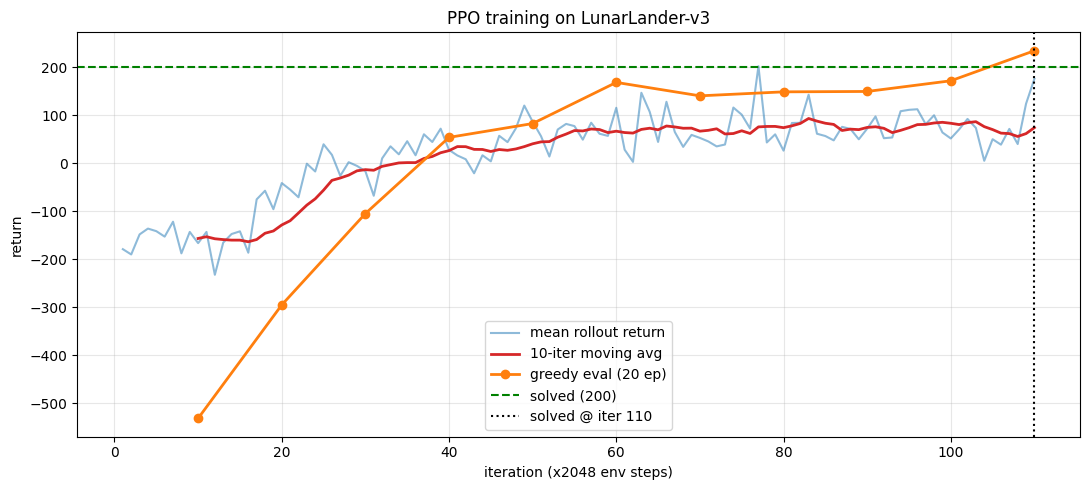

final eval: (110, 234.53964546796692)


In [6]:
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(range(1, len(rollout_curve)+1), rollout_curve, alpha=0.5, label='mean rollout return')
ma = moving_average(rollout_curve, 10)
if len(ma): ax.plot(range(10, 10+len(ma)), ma, color='C3', lw=2, label='10-iter moving avg')
if eval_curve:
    xs, ys = zip(*eval_curve); ax.plot(xs, ys, 'o-', color='C1', lw=2, label='greedy eval (20 ep)')
ax.axhline(200, color='green', ls='--', lw=1.5, label='solved (200)')
if solved_it: ax.axvline(solved_it, color='k', ls=':', label=f'solved @ iter {solved_it}')
ax.set_xlabel('iteration (x2048 env steps)'); ax.set_ylabel('return')
ax.set_title('PPO training on LunarLander-v3'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'ppo_training.png'), dpi=110); plt.show()
print('final eval:', eval_curve[-1] if eval_curve else 'n/a')

**Result.** Policy/value saved to `../models/ppo/`, log to `../logs/ppo/train_log.csv`.
PPO's on-policy updates and clipped objective usually give the **smoothest** learning curve
of the three, at the cost of more environment steps per unit of progress (lower sample
efficiency than the replay-based value methods).